# Agrupamento com Z-score → PCA → K-Means — Grocery Sales
Quarto notebook do projeto (aprendizado **não supervisionado**). É uma segunda abordagem para agrupar os clientes, feita nesta ordem:
1. **Z-score por feature** em uma tabela de características por cliente (todas ficam com média 0 e desvio 1 e pesam igual).
2. **PCA** sobre a tabela padronizada: mostra **quais features** carregam estrutura (cargas e comunalidade) e **quantos componentes** valem a pena manter (comparando com o que o acaso daria).
3. **K-Means** sobre os componentes escolhidos: mostra **quantos grupos** (K) os dados sustentam (inércia, silhouette, Davies-Bouldin, Calinski-Harabasz e gap statistic, comparados com dados sem estrutura).

> Pré-requisito: rodar `limpeza.ipynb` para gerar a pasta `dados_limpos/`. O `agrupamento.ipynb` é opcional (só é usado na seção 10, para comparar os resultados).

## 1. Carregar os dados

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

PASTA = Path("dados_limpos")
AZUL = "#2a6fdb"
SEMENTE = 42

categories = pd.read_csv(PASTA / "categories.csv")
products = pd.read_csv(PASTA / "products.csv", usecols=["ProductID", "Class", "Resistant"])
nomes = categories.set_index("CategoryID")["CategoryName"]
sales = pd.read_csv(PASTA / "sales.csv", usecols=["CustomerID", "ProductID", "CategoryID", "Quantity", "Discount", "UnitPrice", "TotalPrice", "SalesDate"], parse_dates=["SalesDate"], dtype={"CustomerID": "int32", "ProductID": "int32", "CategoryID": "int16", "Quantity": "int32", "Discount": "float32", "UnitPrice": "float32", "TotalPrice": "float32"})
sales["Categoria"] = sales.CategoryID.map(nomes)
print(f"{len(sales):,} vendas | {sales.CustomerID.nunique():,} clientes | {sales.CategoryID.nunique()} categorias")

6,690,599 vendas | 98,759 clientes | 11 categorias


## 2. Tabela de features por cliente
Cada linha é um cliente e cada coluna uma característica dele, em dois blocos:
- **Comportamento**: número de compras, quantidade média por compra, receita total, ticket médio, preço médio do produto e fração das compras com desconto, no fim de semana, de classe *High* e de produtos duráveis.
- **Mistura de categorias**: a **parcela** das compras do cliente em cada categoria (cada linha soma 1). Usamos parcela, e não contagem, para a mistura não repetir a informação do número de compras.

A tabela é larga de propósito e tem features que se sobrepõem (`receita_total` depende de `n_compras` e `quantidade_media`, por exemplo). Quem decide o que realmente importa é o PCA.

In [5]:
vendas = sales.merge(products, on="ProductID", how="left")
vendas["desconto"] = vendas.Discount > 0
vendas["fim_semana"] = vendas.SalesDate.dt.dayofweek >= 5
vendas["classe_high"] = vendas.Class == "High"
vendas["duravel"] = vendas.Resistant == "Durable"

g = vendas.groupby("CustomerID")
comportamento = pd.DataFrame({
    "n_compras": g.size(),
    "quantidade_media": g["Quantity"].mean(),
    "receita_total": g["TotalPrice"].sum().astype("float64"),
    "ticket_medio": g["TotalPrice"].mean(),
    "preco_medio": g["UnitPrice"].mean(),
    "pct_desconto": g["desconto"].mean(),
    "pct_fim_semana": g["fim_semana"].mean(),
    "pct_classe_high": g["classe_high"].mean(),
    "pct_duravel": g["duravel"].mean(),
})

contagem = vendas.groupby(["CustomerID", "Categoria"]).size().unstack(fill_value=0)
mistura = contagem.div(contagem.sum(axis=1), axis=0).add_prefix("parcela_")

X = comportamento.join(mistura).astype("float64")
constantes = X.columns[X.std() == 0]
if len(constantes):
    print("Features sem variação (removidas):", list(constantes))
    X = X.drop(columns=constantes)
print(f"Tabela de features: {X.shape[0]:,} clientes x {X.shape[1]} features")
display(X.describe().T.round(3))

Tabela de features: 98,759 clientes x 20 features


,count,mean,std,min,25%,50%,75%,max
n_compras,98759.0,67.747,8.209,36.000,62.000,68.000,73.000,102.000
quantidade_media,98759.0,13.000,7.211,1.000,7.000,13.000,19.000,25.000
receita_total,98759.0,43431.402,25066.704,1943.717,22085.168,42556.711,63148.244,126585.891
ticket_medio,98759.0,640.929,359.146,37.311,330.805,637.712,943.992,1591.885
preco_medio,98759.0,50.827,3.499,30.618,48.470,50.827,53.180,65.355
pct_desconto,98759.0,0.200,0.049,0.017,0.167,0.198,0.232,0.441
pct_fim_semana,98759.0,0.279,0.055,0.048,0.241,0.278,0.316,0.548
pct_classe_high,98759.0,0.316,0.057,0.103,0.278,0.316,0.354,0.597
pct_duravel,98759.0,0.363,0.059,0.107,0.323,0.362,0.403,0.636
parcela_Beverages,98759.0,0.084,0.034,0.000,0.061,0.082,0.106,0.261


## 3. Z-score por feature
Cada coluna vira `(valor − média) / desvio`. Sem isso, `receita_total` (milhares) dominaria `pct_desconto` (0 a 1) só pela unidade. Depois do Z-score cada feature tem **variância 1**, então a variância total é igual ao número de features e o PCA passa a trabalhar com a **matriz de correlação**.

O mapa de correlações abaixo mostra por que o PCA faz sentido: features muito correlacionadas dizem a mesma coisa e serão resumidas em um mesmo componente.

,n_compras,quantidade_media,receita_total,ticket_medio,preco_medio,pct_desconto,pct_fim_semana,pct_classe_high,pct_duravel,parcela_Beverages,parcela_Cereals,parcela_Confections,parcela_Dairy,parcela_Grain,parcela_Meat,parcela_Poultry,parcela_Produce,parcela_Seafood,parcela_Shell fish,parcela_Snails
mean,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


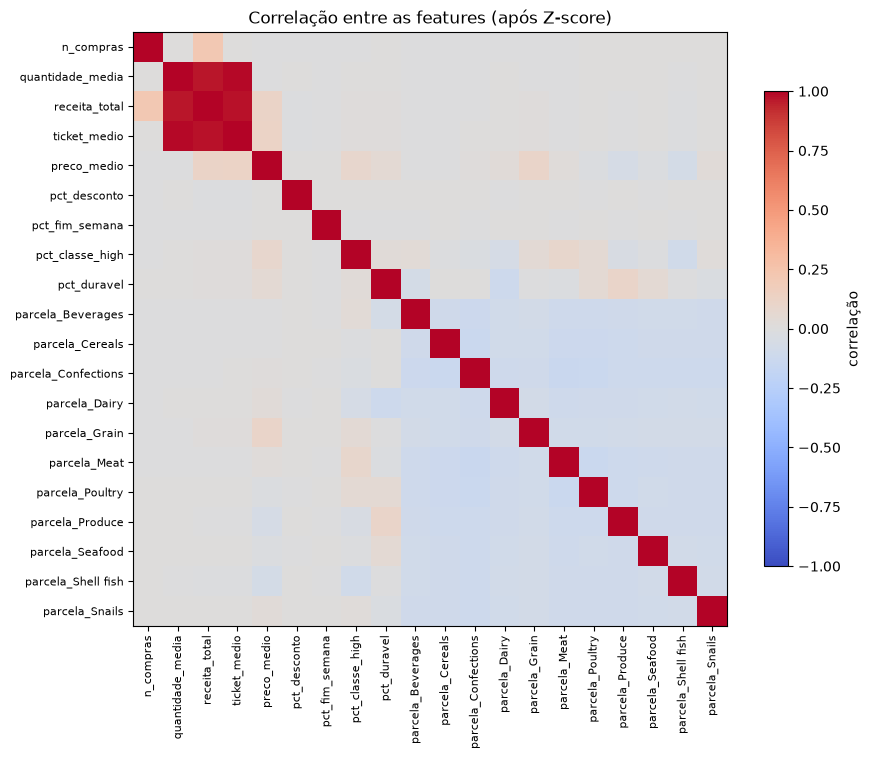

Correlações fora da diagonal: mínima -0.13, máxima 0.99, |r| médio 0.056


In [6]:
escala = StandardScaler()
Z = pd.DataFrame(escala.fit_transform(X), index=X.index, columns=X.columns)
display(Z.agg(["mean", "std"]).T.round(3).T)

corr = Z.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlação")
ax.set(title="Correlação entre as features (após Z-score)"); plt.tight_layout(); plt.show()

fora = corr.values[~np.eye(len(corr), dtype=bool)]
print(f"Correlações fora da diagonal: mínima {fora.min():.2f}, máxima {fora.max():.2f}, |r| médio {np.abs(fora).mean():.3f}")

## 4. PCA: quantos componentes manter
Ajustamos o PCA com **todos** os componentes e olhamos três critérios para decidir quantos manter:
- **Variância acumulada** (`VARIANCIA_ALVO`, por exemplo 80%).
- **Kaiser**: manter componentes com autovalor maior que 1 (explicam mais que uma feature sozinha).
- **Análise paralela** (contra o acaso): geramos clientes **sem estrutura** e refazemos o Z-score e o PCA. No bloco de comportamento, cada coluna é embaralhada de forma independente (destrói as correlações e mantém as distribuições). Na mistura de categorias, cada cliente sorteia suas compras com as probabilidades globais das categorias, como no `agrupamento.ipynb`; isso mantém o efeito de as parcelas somarem 1, que cria correlações negativas leves mesmo sem preferência real. Só vale manter um componente cujo autovalor passa o do acaso (percentil 95 de 20 simulações).

`N_PCS` é a escolha final. Por padrão usa a análise paralela (mínimo de 2 componentes, para poder desenhar o plano PC1 × PC2); troque o valor se preferir outro critério.

,autovalor,variancia_%,acumulada_%,limite_acaso_p95,acima_do_acaso
PC1,2.967,14.834,14.834,1.164,True
PC2,1.280,6.399,21.233,1.147,True
PC3,1.237,6.184,27.417,1.135,True
PC4,1.154,5.772,33.189,1.124,True
PC5,1.129,5.645,38.834,1.114,True
PC6,1.118,5.591,44.425,1.106,True
PC7,1.104,5.521,49.946,1.098,True
PC8,1.100,5.502,55.449,1.089,True
PC9,1.092,5.460,60.908,1.079,True
PC10,1.089,5.445,66.353,1.067,True


Componentes pelo critério de 80% de variância: 13 | Kaiser (autovalor > 1): 13 | análise paralela: 11
N_PCS escolhido: 11 (71.7% da variância)


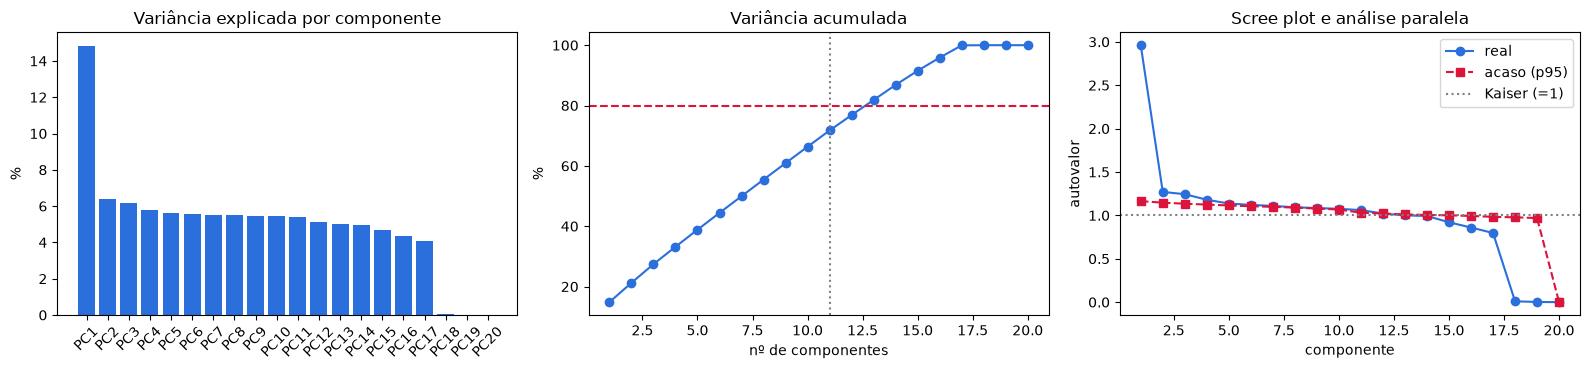

In [7]:
pca_total = PCA(random_state=SEMENTE).fit(Z)
autovalores = pca_total.explained_variance_
var = pca_total.explained_variance_ratio_
acumulada = np.cumsum(var)
nomes_pc = [f"PC{i + 1}" for i in range(len(var))]

# clientes sem estrutura: comportamento embaralhado por coluna + mistura sorteada ao acaso
cols_mistura = [c for c in X.columns if c.startswith("parcela_")]
probs = contagem.sum(axis=0).values / contagem.values.sum()

def gerar_nulo(idx, rng):
    base = X.iloc[idx]
    nulo = pd.DataFrame({c: rng.permutation(base[c].values) for c in X.columns}, index=base.index)
    sorteio = rng.multinomial(base["n_compras"].astype(int).values, probs)
    nulo[cols_mistura] = sorteio / sorteio.sum(axis=1, keepdims=True)
    return StandardScaler().fit_transform(nulo)

# análise paralela: autovalores reais x autovalores de clientes sem estrutura (mesma amostra)
rng = np.random.default_rng(SEMENTE)
amostra = rng.choice(len(Z), min(20000, len(Z)), replace=False)
aut_real_amostra = PCA().fit(Z.values[amostra]).explained_variance_
aut_acaso = np.array([PCA().fit(gerar_nulo(amostra, rng)).explained_variance_ for _ in range(20)])
limite_acaso = np.percentile(aut_acaso, 95, axis=0)

VARIANCIA_ALVO = 0.80
n_variancia = int(np.argmax(acumulada >= VARIANCIA_ALVO) + 1)
n_kaiser = int((autovalores > 1).sum())
acima = aut_real_amostra > limite_acaso
n_acaso = int(len(acima) if acima.all() else np.argmin(acima))

N_PCS = max(2, n_acaso)   # <- troque aqui se preferir outro critério

tabela_pca = pd.DataFrame({"autovalor": autovalores, "variancia_%": var * 100, "acumulada_%": acumulada * 100, "limite_acaso_p95": limite_acaso, "acima_do_acaso": acima}, index=nomes_pc)
display(tabela_pca.round(3))
print(f"Componentes pelo critério de {VARIANCIA_ALVO:.0%} de variância: {n_variancia} | Kaiser (autovalor > 1): {n_kaiser} | análise paralela: {n_acaso}")
print(f"N_PCS escolhido: {N_PCS} ({acumulada[N_PCS - 1]:.1%} da variância)")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].bar(nomes_pc, var * 100, color=AZUL); axes[0].set(title="Variância explicada por componente", ylabel="%")
axes[1].plot(range(1, len(acumulada) + 1), acumulada * 100, "o-", color=AZUL)
axes[1].axhline(VARIANCIA_ALVO * 100, color="crimson", ls="--"); axes[1].axvline(N_PCS, color="gray", ls=":")
axes[1].set(title="Variância acumulada", xlabel="nº de componentes", ylabel="%")
axes[2].plot(range(1, len(autovalores) + 1), aut_real_amostra, "o-", color=AZUL, label="real")
axes[2].plot(range(1, len(autovalores) + 1), limite_acaso, "s--", color="crimson", label="acaso (p95)")
axes[2].axhline(1, color="gray", ls=":", label="Kaiser (=1)")
axes[2].set(title="Scree plot e análise paralela", xlabel="componente", ylabel="autovalor"); axes[2].legend()
for ax in axes[:1]: plt.setp(ax.get_xticklabels(), rotation=45)
plt.tight_layout(); plt.show()

## 5. PCA: quais features pesam em cada componente
- **Cargas** (*loadings*): correlação de cada feature com cada componente, de −1 a 1. Perto de ±1, a feature "é" aquele componente.
- **Comunalidade**: fração da variância de uma feature que os `N_PCS` componentes mantidos conseguem reproduzir (soma dos quadrados das cargas). Como cada feature tem variância 1, vai de 0 a 1. Feature com comunalidade baixa **não é representada** pelos componentes escolhidos: tem informação própria que o PCA descartou (ou ruído).

`LIMIAR_COMUNALIDADE` só marca as features abaixo dele; o K-Means da próxima seção usa os componentes, então essas features pesam pouco no resultado.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
n_compras,0.11,-0.04,0.03,-0.05,0.01,-0.01,-0.01,-0.02,-0.02,-0.02,-0.03
quantidade_media,0.98,-0.07,-0.01,-0.04,0.02,0.01,0.01,0.02,-0.01,-0.01,-0.00
receita_total,0.99,-0.01,-0.00,-0.01,0.00,-0.00,-0.00,-0.00,-0.01,-0.00,-0.00
ticket_medio,0.99,-0.01,-0.01,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.01
preco_medio,0.12,0.50,-0.03,0.31,-0.14,-0.10,-0.04,-0.16,0.04,0.06,0.06
pct_desconto,-0.01,0.02,0.00,0.00,0.02,-0.02,0.04,-0.01,-0.04,-0.05,0.06
pct_fim_semana,-0.00,0.01,-0.02,0.01,-0.04,0.00,-0.03,-0.01,-0.02,-0.00,-0.01
pct_classe_high,0.02,0.60,0.14,-0.14,0.04,0.08,0.08,0.10,-0.02,-0.03,-0.02
pct_duravel,0.02,0.02,0.67,0.10,-0.06,-0.10,-0.04,-0.00,0.00,0.03,0.06
parcela_Beverages,-0.01,0.11,-0.24,-0.27,0.06,0.16,0.76,-0.02,-0.38,0.13,-0.02


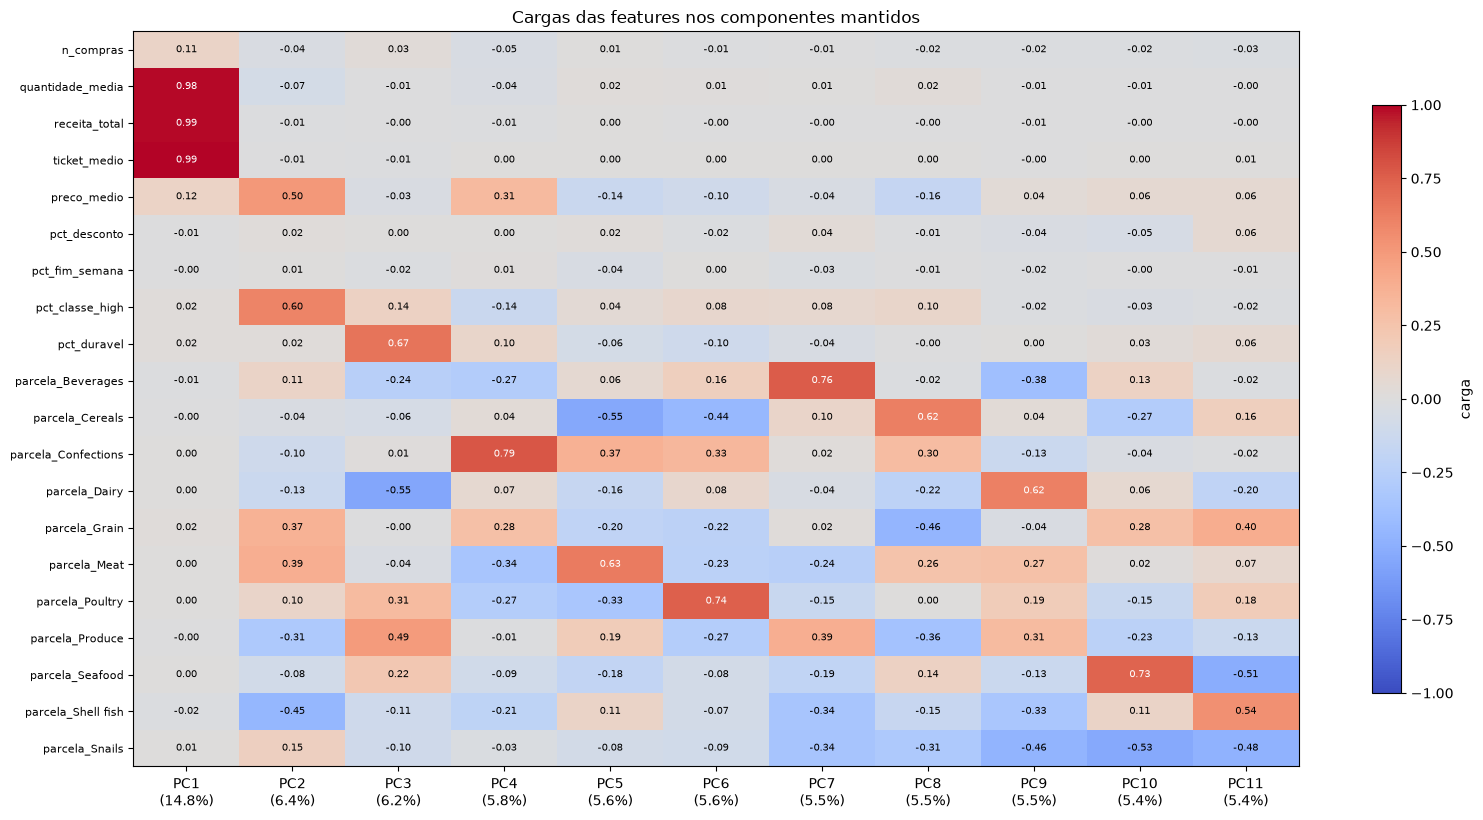

In [8]:
cargas = pd.DataFrame(pca_total.components_.T * np.sqrt(autovalores), index=Z.columns, columns=nomes_pc)
cargas_k = cargas.iloc[:, :N_PCS]
display(cargas_k.round(2))

fig, ax = plt.subplots(figsize=(1.1 * N_PCS + 4, 0.34 * len(cargas_k) + 1.5))
im = ax.imshow(cargas_k.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(N_PCS)); ax.set_xticklabels([f"{c}\n({var[i]:.1%})" for i, c in enumerate(cargas_k.columns)])
ax.set_yticks(range(len(cargas_k))); ax.set_yticklabels(cargas_k.index, fontsize=8)
for i in range(cargas_k.shape[0]):
    for j in range(N_PCS):
        ax.text(j, i, f"{cargas_k.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(cargas_k.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="carga"); ax.set(title="Cargas das features nos componentes mantidos"); plt.tight_layout(); plt.show()

,comunalidade,componente_principal,representada
parcela_Cereals,0.997,PC8,True
parcela_Confections,0.991,PC4,True
ticket_medio,0.986,PC1,True
parcela_Snails,0.986,PC10,True
receita_total,0.983,PC1,True
quantidade_media,0.977,PC1,True
parcela_Seafood,0.971,PC10,True
parcela_Poultry,0.952,PC6,True
parcela_Meat,0.930,PC5,True
parcela_Beverages,0.919,PC7,True


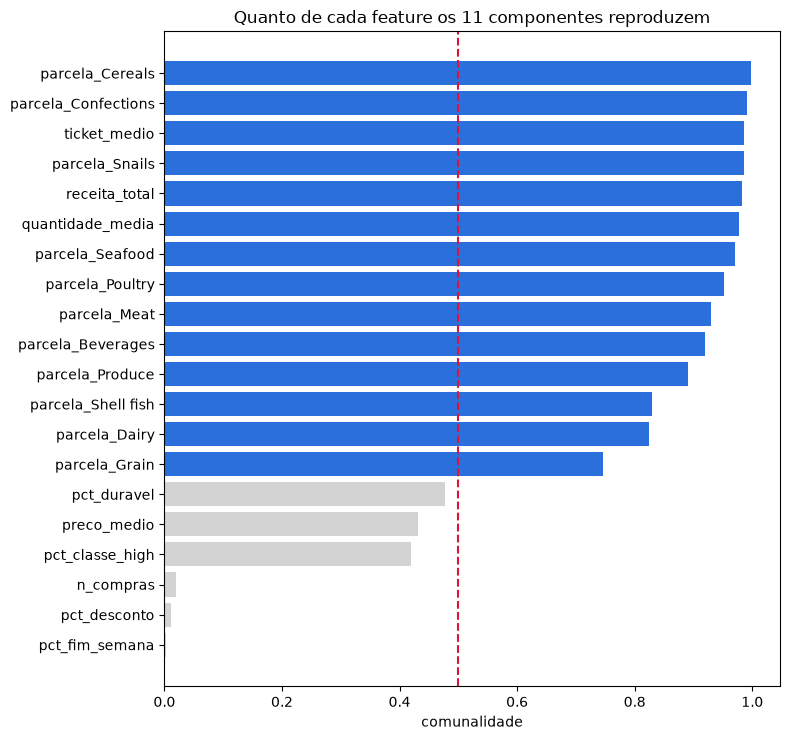

Features que o PCA mantém: parcela_Cereals, parcela_Confections, ticket_medio, parcela_Snails, receita_total, quantidade_media, parcela_Seafood, parcela_Poultry, parcela_Meat, parcela_Beverages, parcela_Produce, parcela_Shell fish, parcela_Dairy, parcela_Grain
Features pouco representadas: pct_duravel, preco_medio, pct_classe_high, n_compras, pct_desconto, pct_fim_semana


In [9]:
LIMIAR_COMUNALIDADE = 0.5

comunalidade = (cargas_k ** 2).sum(axis=1).sort_values(ascending=False)
importancia = pd.DataFrame({"comunalidade": comunalidade, "componente_principal": cargas_k.abs().idxmax(axis=1).loc[comunalidade.index], "representada": comunalidade >= LIMIAR_COMUNALIDADE})
display(importancia.round(3))

fig, ax = plt.subplots(figsize=(8, 0.3 * len(comunalidade) + 1.5))
ax.barh(comunalidade.index[::-1], comunalidade.values[::-1], color=[AZUL if v >= LIMIAR_COMUNALIDADE else "lightgray" for v in comunalidade.values[::-1]])
ax.axvline(LIMIAR_COMUNALIDADE, color="crimson", ls="--")
ax.set(title=f"Quanto de cada feature os {N_PCS} componentes reproduzem", xlabel="comunalidade"); plt.tight_layout(); plt.show()

print("Features que o PCA mantém:", ", ".join(importancia.index[importancia.representada]))
print("Features pouco representadas:", ", ".join(importancia.index[~importancia.representada]) or "nenhuma")

## 6. Escores: os clientes no espaço dos componentes
O K-Means roda sobre os **escores** (as coordenadas de cada cliente nos `N_PCS` primeiros componentes). Os escores não são padronizados de novo: manter a variância de cada componente preserva a importância relativa deles nas distâncias.

Escores: 98,759 clientes x 11 componentes | desvio de cada componente: [1.72 1.13 1.11 1.07 1.06 1.06 1.05 1.05 1.04 1.04 1.04]


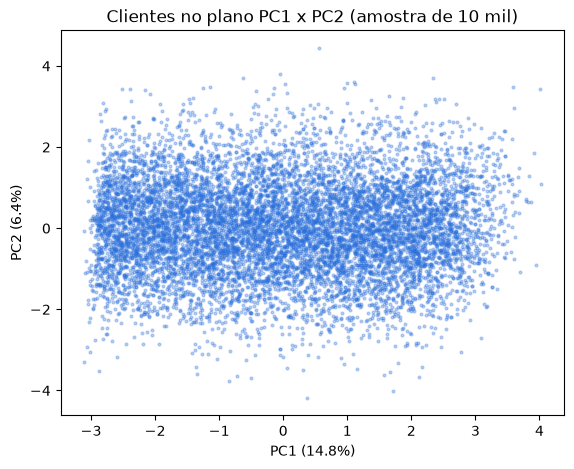

In [10]:
escores = pca_total.transform(Z)[:, :N_PCS]
print(f"Escores: {escores.shape[0]:,} clientes x {escores.shape[1]} componentes | desvio de cada componente:", np.round(escores.std(axis=0), 2))

idx_plot = np.random.RandomState(SEMENTE).choice(len(escores), min(10000, len(escores)), replace=False)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(escores[idx_plot, 0], escores[idx_plot, 1], s=4, alpha=0.3, color=AZUL)
ax.set(title="Clientes no plano PC1 x PC2 (amostra de 10 mil)", xlabel=f"PC1 ({var[0]:.1%})", ylabel=f"PC2 ({var[1]:.1%})"); plt.show()

## 7. K-Means: quantos grupos
Testamos de 2 a 10 grupos sobre os escores e medimos:
- **Inércia** (cotovelo): soma das distâncias ao centro; sempre cai com mais grupos.
- **Silhouette** (−1 a 1): separação entre grupos. Aqui vem junto a silhouette **ao acaso**: a mesma conta (PCA + K-Means) nos clientes sem estrutura da seção 4. Se a real não passa a do acaso, o K-Means está só cortando uma nuvem sem estrutura.
- **Davies-Bouldin** (menor é melhor) e **Calinski-Harabasz** (maior é melhor).
- **Variância explicada pelos grupos**: `1 − inércia / variância total` dos escores.
- **Gap statistic**: compara a inércia dos dados com a de dados uniformes sem grupos. Gap perto de 0 (ou negativo) significa que não há agrupamento natural. Regra de escolha de Tibshirani: o menor K tal que `gap(K) ≥ gap(K+1) − erro(K+1)`. Cuidado: com vários componentes, o gap contra dados uniformes costuma sair positivo até sem grupos (uma nuvem concentrada sempre é mais compacta que uma caixa uniforme). Por isso calculamos também o **gap ao acaso** (mesma conta nos clientes sem estrutura) e o que vale é a diferença entre os dois.

,inercia,silhouette,silhouette_acaso,davies_bouldin,calinski_harabasz,variancia_explicada_%,gap,gap_erro,gap_acaso
k,,,,,,,,,
2,1199537.194,0.140,0.062,2.295,17890.185,15.337,1.663,0.002,1.574
3,1154178.358,0.084,0.056,3.053,11237.217,18.538,1.648,0.003,1.566
4,1114984.932,0.062,0.057,3.432,8911.847,21.305,1.639,0.002,1.564
5,1085823.895,0.058,0.059,3.147,7526.353,23.363,1.636,0.002,1.568
6,1059402.316,0.058,0.060,3.017,6663.763,25.228,1.633,0.002,1.571
7,1036683.593,0.058,0.061,2.878,6035.450,26.831,1.631,0.002,1.574
8,1015853.491,0.057,0.062,2.757,5568.544,28.301,1.627,0.002,1.576
9,996945.778,0.059,0.063,2.669,5198.931,29.636,1.626,0.002,1.580
10,979272.003,0.059,0.064,2.588,4902.655,30.883,1.627,0.002,1.584


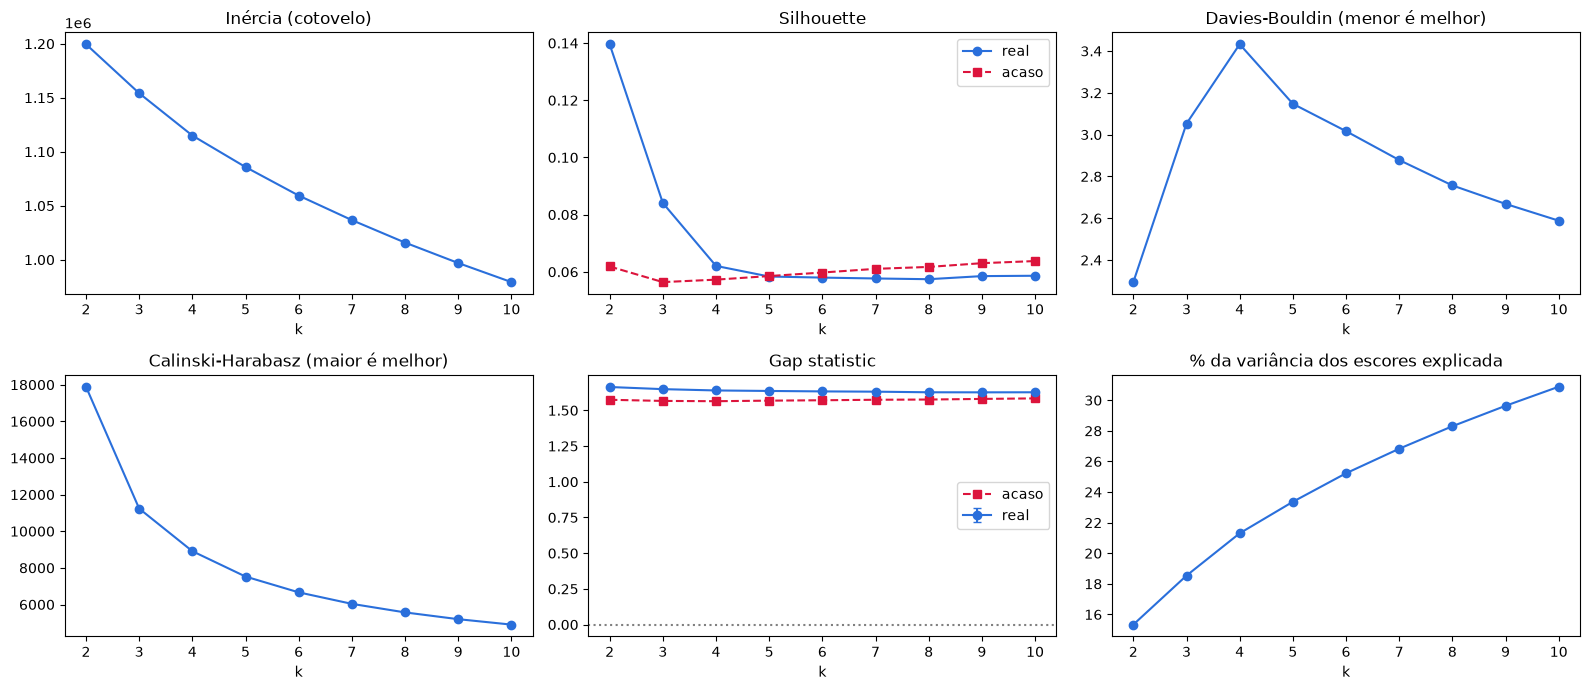

In [11]:
rng = np.random.RandomState(SEMENTE)
amostra_q = rng.choice(len(escores), min(10000, len(escores)), replace=False)
amostra_gap = escores[rng.choice(len(escores), min(20000, len(escores)), replace=False)]
referencias = [rng.uniform(amostra_gap.min(axis=0), amostra_gap.max(axis=0), size=amostra_gap.shape) for _ in range(10)]

# clientes sem estrutura (seção 4), passando pelo mesmo Z-score + PCA
idx_nulo = rng.choice(len(Z), min(10000, len(Z)), replace=False)
escores_nulo = PCA(n_components=N_PCS, random_state=SEMENTE).fit_transform(gerar_nulo(idx_nulo, np.random.default_rng(SEMENTE)))
referencias_nulo = [rng.uniform(escores_nulo.min(axis=0), escores_nulo.max(axis=0), size=escores_nulo.shape) for _ in range(10)]

def log_inercia(x, k):
    return np.log(KMeans(n_clusters=k, n_init=5, random_state=SEMENTE).fit(x).inertia_)

def gap(x, refs, k):
    return np.mean([log_inercia(r, k) for r in refs]) - log_inercia(x, k)

variancia_total = ((escores - escores.mean(axis=0)) ** 2).sum()
linhas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit(escores)
    rot = km.labels_
    ref = np.array([log_inercia(r, k) for r in referencias])
    rot_nulo = KMeans(n_clusters=k, n_init=5, random_state=SEMENTE).fit_predict(escores_nulo)
    linhas.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(escores[amostra_q], rot[amostra_q]), "silhouette_acaso": silhouette_score(escores_nulo, rot_nulo),
                   "davies_bouldin": davies_bouldin_score(escores, rot), "calinski_harabasz": calinski_harabasz_score(escores, rot),
                   "variancia_explicada_%": (1 - km.inertia_ / variancia_total) * 100,
                   "gap": ref.mean() - log_inercia(amostra_gap, k), "gap_erro": ref.std() * np.sqrt(1 + 1 / len(ref)), "gap_acaso": gap(escores_nulo, referencias_nulo, k)})
sim_k = pd.DataFrame(linhas).set_index("k")
display(sim_k.round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
axes = axes.ravel()
axes[0].plot(sim_k.index, sim_k.inercia, "o-", color=AZUL); axes[0].set(title="Inércia (cotovelo)", xlabel="k")
axes[1].plot(sim_k.index, sim_k.silhouette, "o-", color=AZUL, label="real"); axes[1].plot(sim_k.index, sim_k.silhouette_acaso, "s--", color="crimson", label="acaso")
axes[1].set(title="Silhouette", xlabel="k"); axes[1].legend()
axes[2].plot(sim_k.index, sim_k.davies_bouldin, "o-", color=AZUL); axes[2].set(title="Davies-Bouldin (menor é melhor)", xlabel="k")
axes[3].plot(sim_k.index, sim_k.calinski_harabasz, "o-", color=AZUL); axes[3].set(title="Calinski-Harabasz (maior é melhor)", xlabel="k")
axes[4].errorbar(sim_k.index, sim_k.gap, yerr=sim_k.gap_erro, fmt="o-", color=AZUL, capsize=3, label="real"); axes[4].plot(sim_k.index, sim_k.gap_acaso, "s--", color="crimson", label="acaso")
axes[4].axhline(0, color="gray", ls=":"); axes[4].set(title="Gap statistic", xlabel="k"); axes[4].legend()
axes[5].plot(sim_k.index, sim_k["variancia_explicada_%"], "o-", color=AZUL); axes[5].set(title="% da variância dos escores explicada", xlabel="k")
plt.tight_layout(); plt.show()

In [12]:
k_sil = int(sim_k.silhouette.idxmax())
k_db = int(sim_k.davies_bouldin.idxmin())
k_ch = int(sim_k.calinski_harabasz.idxmax())
k_gap = next((k for k in sim_k.index[:-1] if sim_k.gap[k] >= sim_k.gap[k + 1] - sim_k.gap_erro[k + 1]), None)
acima_acaso = (sim_k.silhouette - sim_k.silhouette_acaso).round(3)

print(f"Melhor K pela silhouette: {k_sil} | Davies-Bouldin: {k_db} | Calinski-Harabasz: {k_ch} | gap (Tibshirani): {k_gap}")
print("Silhouette real menos silhouette ao acaso, por K:", acima_acaso.to_dict())
print("Gap real menos gap ao acaso, por K:", (sim_k.gap - sim_k.gap_acaso).round(3).to_dict())

K_FINAL = k_sil   # <- troque aqui se os critérios divergirem ou se preferir outro K
print(f"K_FINAL usado nas próximas seções: {K_FINAL}")

Melhor K pela silhouette: 2 | Davies-Bouldin: 2 | Calinski-Harabasz: 2 | gap (Tibshirani): 2
Silhouette real menos silhouette ao acaso, por K: {2: 0.078, 3: 0.028, 4: 0.005, 5: -0.0, 6: -0.002, 7: -0.003, 8: -0.004, 9: -0.005, 10: -0.005}
Gap real menos gap ao acaso, por K: {2: 0.089, 3: 0.082, 4: 0.075, 5: 0.068, 6: 0.062, 7: 0.057, 8: 0.051, 9: 0.046, 10: 0.043}
K_FINAL usado nas próximas seções: 2


## 8. Fechar os grupos e dar nomes
Os grupos são ordenados da **maior para a menor receita média** e recebem as letras A, B, C… Os nomes ficam em `NOMES_GRUPOS`: use "Grupo A" etc. como chave e o nome como valor. Sem nome, o grupo aparece só com a letra.

Depois do ajuste vem a checagem de **estabilidade**: refazer o K-Means com outras sementes e com metade dos clientes e medir o quanto os grupos coincidem (ARI = 1 é idêntico, perto de 0 é aleatório). Grupos que mudam a cada semente não são grupos reais.

In [13]:
NOMES_GRUPOS = {
    # "Grupo A": "nome do grupo",
}

km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEMENTE).fit(escores)
ordem = X.groupby(km_final.labels_)["receita_total"].mean().sort_values(ascending=False).index
nome_cluster = {c: NOMES_GRUPOS.get(f"Grupo {chr(65 + i)}", f"Grupo {chr(65 + i)}") for i, c in enumerate(ordem)}
grupo = pd.Series(km_final.labels_, index=X.index).map(nome_cluster).rename("Grupo")
ordem_nomes = [nome_cluster[c] for c in ordem]

# estabilidade
rotulos_sementes = [KMeans(n_clusters=K_FINAL, n_init=5, random_state=s).fit_predict(escores) for s in range(5)]
ari_sementes = [adjusted_rand_score(rotulos_sementes[0], r) for r in rotulos_sementes[1:]]
metade = np.random.RandomState(SEMENTE).rand(len(escores)) < 0.5
pred_metade = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEMENTE).fit(escores[metade]).predict(escores)
print(f"ARI entre sementes diferentes: {np.round(ari_sementes, 3).tolist()}")
print(f"ARI entre ajuste com metade dos clientes e ajuste completo: {adjusted_rand_score(km_final.labels_, pred_metade):.3f}")

tamanho_g = grupo.value_counts().loc[ordem_nomes]
print("\nTamanho dos grupos:", {n: f"{v:,} ({v / len(grupo):.1%})" for n, v in tamanho_g.items()})

ARI entre sementes diferentes: [0.999, 0.999, 0.999, 0.999]
ARI entre ajuste com metade dos clientes e ajuste completo: 0.995

Tamanho dos grupos: {'Grupo A': '48,838 (49.5%)', 'Grupo B': '49,921 (50.5%)'}


## 9. Perfil dos grupos
- **Médias nas unidades originais**: o que cada grupo faz, em linguagem de negócio.
- **Z-score médio por grupo**: onde cada grupo está acima (vermelho) ou abaixo (azul) da média geral, em desvios. Mostra quais features **separam** os grupos.
- **η² por feature**: fração da variação de cada feature explicada pelo agrupamento. É o teste final de "considerando quais features": feature com η² perto de 0 não diferencia os grupos, mesmo que o PCA a tenha mantido.

,Grupo A,Grupo B
n_compras,68.303,67.203
quantidade_media,19.260,6.875
receita_total,64903.602,22425.026
ticket_medio,952.696,335.926
preco_medio,51.061,50.599
pct_desconto,0.200,0.200
pct_fim_semana,0.279,0.279
pct_classe_high,0.317,0.316
pct_duravel,0.364,0.362
parcela_Beverages,0.084,0.084


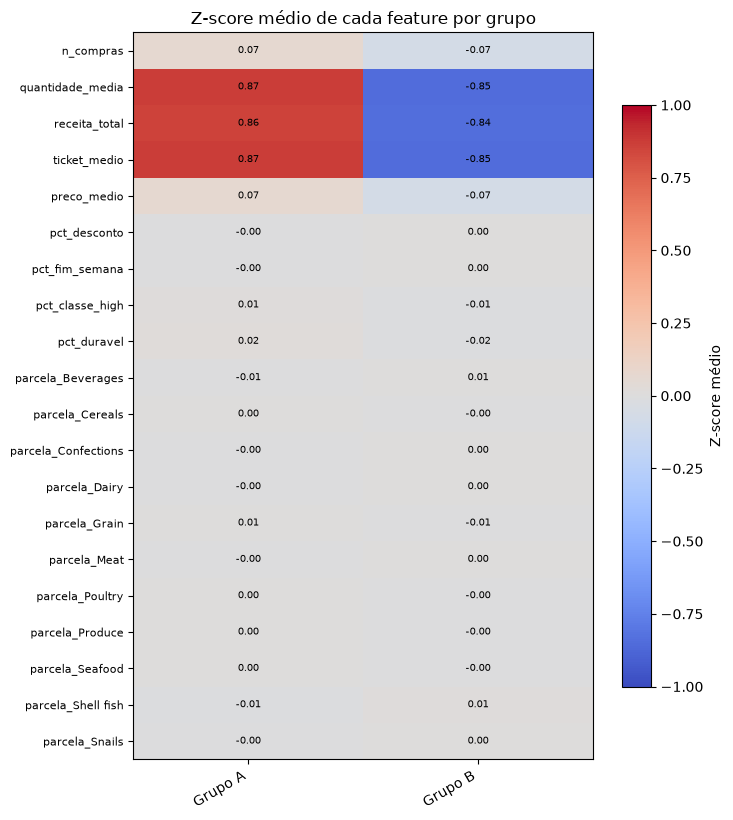

,eta2,esperado_acaso
quantidade_media,0.7374,0.0
ticket_medio,0.7372,0.0
receita_total,0.7179,0.0
n_compras,0.0045,0.0
preco_medio,0.0043,0.0
pct_duravel,0.0002,0.0
pct_classe_high,0.0001,0.0
parcela_Shell fish,0.0001,0.0
parcela_Grain,0.0001,0.0
parcela_Beverages,0.0001,0.0


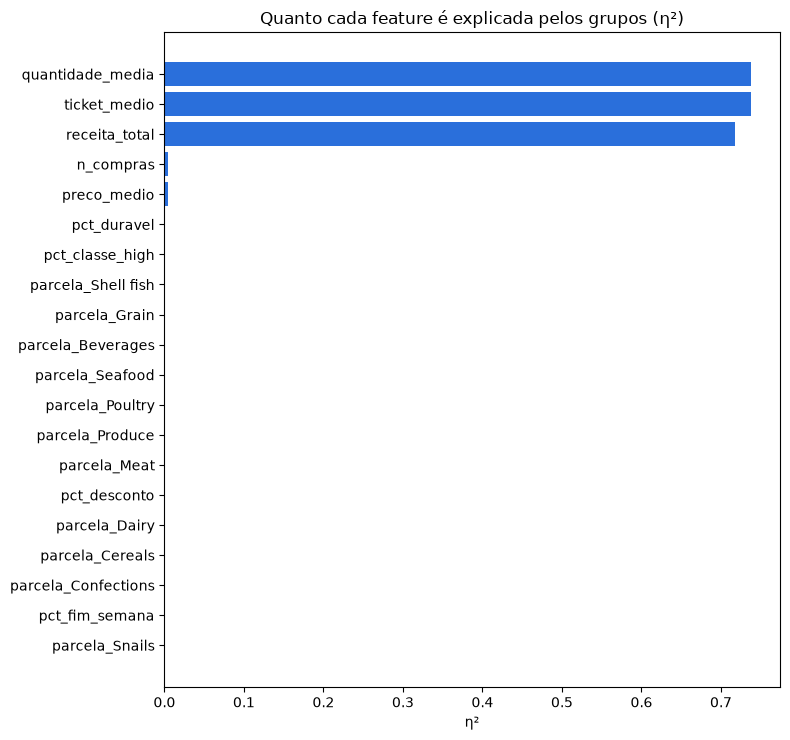

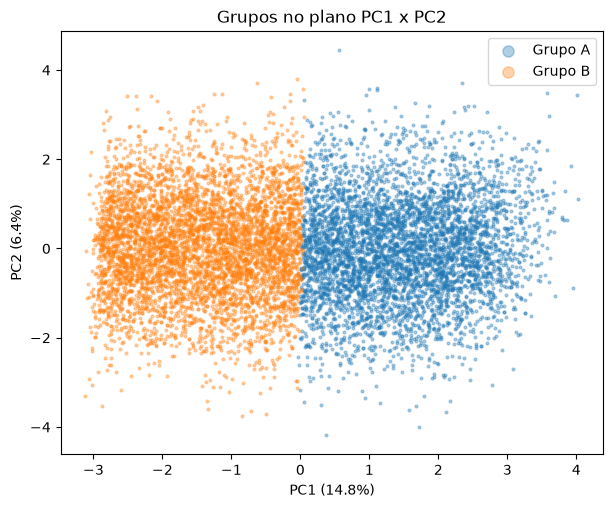

In [14]:
resumo = X.groupby(grupo).mean().loc[ordem_nomes].T
resumo.columns.name = None
display(resumo.round(3))

z_grupo = Z.groupby(grupo).mean().loc[ordem_nomes].T
fig, ax = plt.subplots(figsize=(1.2 * K_FINAL + 5, 0.34 * len(z_grupo) + 1.5))
lim = max(1.0, float(np.abs(z_grupo.values).max()))
im = ax.imshow(z_grupo.values, cmap="coolwarm", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(K_FINAL)); ax.set_xticklabels(z_grupo.columns, rotation=30, ha="right")
ax.set_yticks(range(len(z_grupo))); ax.set_yticklabels(z_grupo.index, fontsize=8)
for i in range(z_grupo.shape[0]):
    for j in range(K_FINAL):
        ax.text(j, i, f"{z_grupo.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="Z-score médio"); ax.set(title="Z-score médio de cada feature por grupo"); plt.tight_layout(); plt.show()

def eta2(valor, grupo_):
    g_ = valor.groupby(grupo_)
    return (g_.size() * (g_.mean() - valor.mean()) ** 2).sum() / ((valor - valor.mean()) ** 2).sum()

esperado_acaso = (K_FINAL - 1) / (len(Z) - 1)
eta = pd.Series({c: eta2(Z[c], grupo) for c in Z.columns}).sort_values(ascending=False)
display(pd.DataFrame({"eta2": eta, "esperado_acaso": esperado_acaso}).round(4))

fig, ax = plt.subplots(figsize=(8, 0.3 * len(eta) + 1.5))
ax.barh(eta.index[::-1], eta.values[::-1], color=AZUL)
ax.set(title="Quanto cada feature é explicada pelos grupos (η²)", xlabel="η²"); plt.tight_layout(); plt.show()

idx_plot = np.random.RandomState(SEMENTE).choice(len(escores), min(10000, len(escores)), replace=False)
paleta = dict(zip(ordem_nomes, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(7, 5.5))
for n in ordem_nomes:
    m = (grupo.values[idx_plot] == n)
    ax.scatter(escores[idx_plot][m, 0], escores[idx_plot][m, 1], s=4, alpha=0.35, color=paleta[n], label=n)
ax.set(title="Grupos no plano PC1 x PC2", xlabel=f"PC1 ({var[0]:.1%})", ylabel=f"PC2 ({var[1]:.1%})")
ax.legend(markerscale=4); plt.show()

## 10. Comparação com o agrupamento anterior
Se o `agrupamento.ipynb` já foi rodado, cruzamos os grupos novos com os grupos de **tamanho de compra** de `clientes_grupos.csv`. ARI perto de 1 significa que os dois métodos chegaram à mesma divisão; perto de 0, a divisões diferentes. Também vemos com quais componentes a `quantidade_media` mais se correlaciona.

In [15]:
print("Correlação da quantidade média com cada componente:", {c: round(float(cargas.loc["quantidade_media", c]), 2) for c in cargas_k.columns})

arquivo_antigo = PASTA / "clientes_grupos.csv"
if arquivo_antigo.exists():
    antigo = pd.read_csv(arquivo_antigo, usecols=["CustomerID", "Grupo"]).set_index("CustomerID")["Grupo"].rename("Grupo_anterior")
    juntos = pd.concat([grupo, antigo], axis=1, join="inner")
    print(f"ARI entre os grupos novos e os de tamanho de compra: {adjusted_rand_score(juntos.Grupo_anterior, juntos.Grupo):.3f}")
    display((pd.crosstab(juntos.Grupo, juntos.Grupo_anterior, normalize="index") * 100).round(1).loc[ordem_nomes])
else:
    print("clientes_grupos.csv não encontrado: rode o agrupamento.ipynb para comparar.")

Correlação da quantidade média com cada componente: {'PC1': 0.98, 'PC2': -0.07, 'PC3': -0.01, 'PC4': -0.04, 'PC5': 0.02, 'PC6': 0.01, 'PC7': 0.01, 'PC8': 0.02, 'PC9': -0.01, 'PC10': -0.01, 'PC11': -0.0}
clientes_grupos.csv não encontrado: rode o agrupamento.ipynb para comparar.


## 11. Salvar

In [16]:
saida = pd.DataFrame(escores, index=X.index, columns=cargas_k.columns).join(grupo).join(X[["receita_total", "quantidade_media", "n_compras"]]).reset_index()
saida.to_csv(PASTA / "clientes_pca_kmeans.csv", index=False)
cargas.round(4).rename_axis("Feature").reset_index().to_csv(PASTA / "pca_cargas.csv", index=False)
importancia.round(4).rename_axis("Feature").reset_index().to_csv(PASTA / "pca_comunalidade.csv", index=False)
sim_k.round(4).reset_index().to_csv(PASTA / "kmeans_simulacao_k.csv", index=False)
print(f"salvo: clientes_pca_kmeans.csv ({len(saida):,} clientes), pca_cargas.csv, pca_comunalidade.csv e kmeans_simulacao_k.csv em {PASTA}")

salvo: clientes_pca_kmeans.csv (98,759 clientes), pca_cargas.csv, pca_comunalidade.csv e kmeans_simulacao_k.csv em dados_limpos


## 12. Como ler os resultados e conclusões
Preencha esta seção depois de rodar, respondendo com os números das tabelas acima:
- **Quais features** (seções 4 e 5): quantos componentes passaram da análise paralela e quanta variância eles têm. Quais features têm comunalidade alta (carregam a estrutura) e quais ficaram de fora.
- **Quantos grupos** (seção 7): os critérios concordam num mesmo K? A silhouette real é maior que a do acaso? O gap real fica acima do gap ao acaso? Se silhouette e gap não passam do acaso, o K é uma **escolha prática**, e não um K natural, como já aconteceu no `agrupamento.ipynb`.
- **Estabilidade** (seção 8): ARI alto entre sementes e entre metades indica grupos reprodutíveis.
- **O que separa os grupos** (seção 9): features com η² bem acima do acaso são as que de fato diferenciam os clientes.
- **Comparação** (seção 10): o PCA + K-Means redescobre o tamanho de compra, ou encontra algo novo?